In [ ]:
from google.colab import files

uploaded = files.upload()

Saving df_filtered.csv to df_filtered.csv


In [ ]:
import pandas as pd

# Read the uploaded CSV file into a pandas DataFrame
df = pd.read_csv('df_filtered.csv')

# Keep only the first 100002 rows
df_filtered = df.head(100002)

# Display the first few rows and the shape of the filtered DataFrame to verify
display(df_filtered.head())
print(f"Shape of the filtered DataFrame: {df_filtered.shape}")

,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment
0,0,NC and NH.,Trumpbart,politics,2,-1,-1,2016-10,2016-10-16 23:55:23,"Yeah, I get that argument. At this point, I'd ..."
1,0,You do know west teams play against west teams...,Shbshb906,nba,-4,-1,-1,2016-11,2016-11-01 00:24:10,The blazers and Mavericks (The wests 5 and 6 s...
2,0,"They were underdogs earlier today, but since G...",Creepeth,nfl,3,3,0,2016-09,2016-09-22 21:45:37,They're favored to win.
3,0,"This meme isn't funny none of the ""new york ni...",icebrotha,BlackPeopleTwitter,-8,-1,-1,2016-10,2016-10-18 21:03:47,deadass don't kill my buzz
4,0,I could use one of those tools.,cush2push,MaddenUltimateTeam,6,-1,-1,2016-12,2016-12-30 17:00:13,Yep can confirm I saw the tool they use for th...


Shape of the filtered DataFrame: (100002, 10)


In [ ]:
# Drop rows with missing values in the 'comment' column and create an explicit copy
df_cleaned = df_filtered.dropna(subset=['comment']).copy()

# Display the new shape of the DataFrame
print(f"Shape of the DataFrame after dropping missing 'comment' values: {df_cleaned.shape}")

Shape of the DataFrame after dropping missing 'comment' values: (99999, 10)


In [ ]:
# Display summary statistics for numerical columns
display("Summary statistics for numerical columns:", df_cleaned.describe())

# Display summary statistics for object (categorical) columns
display("Summary statistics for categorical columns:", df_cleaned.describe(include='object'))

'Summary statistics for numerical columns:'

,label,score,ups,downs
count,99999.000000,99999.000000,99999.000000,99999.000000
mean,0.423084,8.247702,0.873459,-0.785558
std,0.494051,55.932843,23.254951,0.410437
min,0.000000,-298.000000,-261.000000,-1.000000
25%,0.000000,1.000000,-1.000000,-1.000000
50%,0.000000,2.000000,-1.000000,-1.000000
75%,1.000000,5.000000,-1.000000,-1.000000
max,1.000000,5629.000000,3385.000000,0.000000


'Summary statistics for categorical columns:'

,comment,author,subreddit,date,created_utc,parent_comment
count,99999,99999,99999,99999,99999,99999
unique,96933,64374,5412,4,99385,98089
top,You forgot the,sleaze_bag_alert,AskReddit,2016-12,2016-11-02 10:09:10,me irl
freq,165,80,6291,28894,3,47


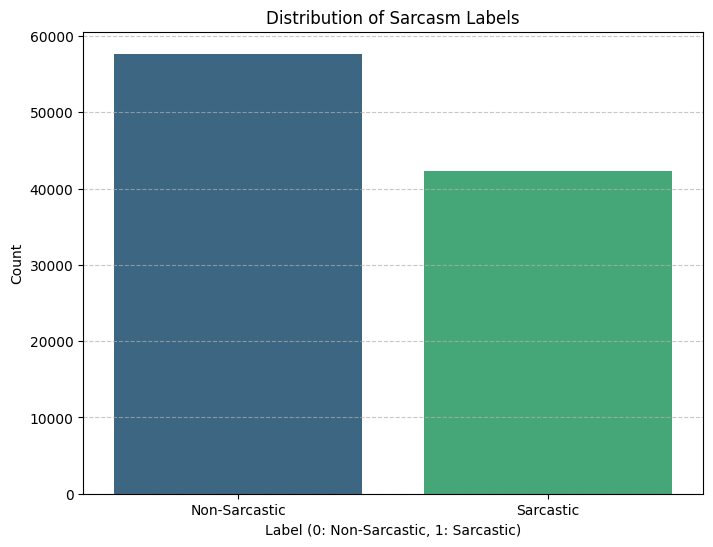

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of the 'label' column
plt.figure(figsize=(8, 6))
sns.countplot(x='label', hue='label', data=df_cleaned, palette='viridis', legend=False)
plt.title('Distribution of Sarcasm Labels')
plt.xlabel('Label (0: Non-Sarcastic, 1: Sarcastic)')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Non-Sarcastic', 'Sarcastic'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# Calculate the average 'score' for sarcastic (label=1) vs non-sarcastic (label=0) comments
average_score_by_label = df_cleaned.groupby('label')['score'].mean().reset_index()

# Display the results
display("Average score for sarcastic vs non-sarcastic comments:", average_score_by_label)


'Average score for sarcastic vs non-sarcastic comments:'

,label,score
0,0,8.596610
1,1,7.771934


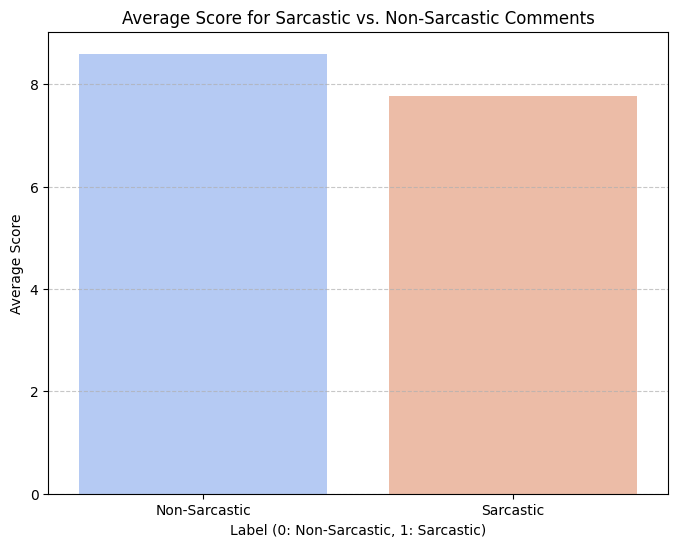

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar plot for the average scores
plt.figure(figsize=(8, 6))
sns.barplot(x='label', y='score', hue='label', data=average_score_by_label, palette='coolwarm', legend=False)
plt.title('Average Score for Sarcastic vs. Non-Sarcastic Comments')
plt.xlabel('Label (0: Non-Sarcastic, 1: Sarcastic)')
plt.ylabel('Average Score')
plt.xticks(ticks=[0, 1], labels=['Non-Sarcastic', 'Sarcastic'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Text Preprocessing

I will now preprocess the text data in the 'comment' column by performing the following steps:
1.  **Remove URLs**: URLs will be replaced with an empty string.
2.  **Remove HTML/XML Tags**: Any HTML or XML tags will be removed.
3.  **Preserve Capitalization and Key Punctuation**: The preprocessing will avoid converting text to lowercase or aggressively removing all punctuation, as specified.

In [ ]:
import re

def preprocess_text(text):
    # 1. Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # 2. Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    return text

# Apply the preprocessing function to the 'comment' column
df_cleaned.loc[:, 'comment_preprocessed'] = df_cleaned['comment'].apply(preprocess_text)

# Display the first few rows with the new preprocessed column
display(df_cleaned[['comment', 'comment_preprocessed']].head())

,comment,comment_preprocessed
0,NC and NH.,NC and NH.
1,You do know west teams play against west teams...,You do know west teams play against west teams...
2,"They were underdogs earlier today, but since G...","They were underdogs earlier today, but since G..."
3,"This meme isn't funny none of the ""new york ni...","This meme isn't funny none of the ""new york ni..."
4,I could use one of those tools.,I could use one of those tools.


In [ ]:
# Check for null values in the 'comment_preprocessed' column
null_preprocessed_comments = df_cleaned['comment_preprocessed'].isnull().sum()
print(f"Number of null values in 'comment_preprocessed' column: {null_preprocessed_comments}")

Number of null values in 'comment_preprocessed' column: 0


### Comparison of Original and Preprocessed Text

Let's examine a few random samples to observe the changes made during preprocessing.

In [ ]:
# Display a few random samples to compare original and preprocessed comments
display(df_cleaned[['comment', 'comment_preprocessed']].sample(5, random_state=42))

,comment,comment_preprocessed
26003,Is that really what it is?,Is that really what it is?
80423,Because space is crazy-big.,Because space is crazy-big.
19865,"Wow, that cut deep bro.","Wow, that cut deep bro."
81528,no thx,no thx
57880,A big ol punper,A big ol punper


### Internet Slang Lexicon

Based on the provided list, I've created a Python dictionary that maps common internet slang terms to their explanations. This lexicon can be useful for further text analysis, such as identifying, counting, or potentially standardizing these terms.

In [ ]:
internet_slang_lexicon = {
    'lol': 'Laughing out loud',
    'bro': 'Brother / friend',
    'wtf': 'What the f***',
    'imo': 'In my opinion',
    'lmao': 'Laughing my a off',
    'idk': 'I don\'t know',
    'tbh': 'To be honest',
    'omg': 'Oh my god',
    'pls': 'Please',
    'cap': 'Lie / False',
    'cuz': 'Because',
    'btw': 'By the way',
    'irl': 'In real life',
    'af': 'As f***',
    'bs': 'Bullsh*t',
    'smh': 'Shaking my head',
    'ama': 'Ask me anything',
    'fam': 'Family / close friends',
    'bc': 'Because',
    'bruh': 'Brother / an expression of disbelief',
    'goat': 'Greatest of all time',
    'plz': 'Please',
    'fyi': 'For your information',
    'lit': 'Amazing / exciting',
    'ik': 'I know',
    'ffs': 'For f***\'s sake',
    'gtfo': 'Get the f*** out',
    'lmfao': 'Laughing my f*ing a off',
    'tldr': 'Too long; didn\'t read',
    'thx': 'Thanks',
    'rn': 'Right now',
    'np': 'No problem',
    'jk': 'Just kidding',
    'ftw': 'For the win',
    'tf': 'The f***',
    'tbf': 'To be fair',
    'brb': 'Be right back',
    'imho': 'In my humble opinion',
    'ikr': 'I know, right?',
    'stfu': 'Shut the f*** up',
    'bae': 'Before anyone else / Babe',
    'mf': 'Motherf***er',
    'fr': 'For real',
    'yolo': 'You only live once',
    'fml': 'F*** my life',
    'rofl': 'Rolling on the floor laughing',
    'nvm': 'Nevermind',
    'idc': 'I don\'t care',
    'hmu': 'Hit me up',
    'dafuq': 'What the f***',
    'wyd': 'What you doing?',
    'sus': 'Suspicious',
    'bff': 'Best friends forever',
    'ngl': 'Not gonna lie',
    'deadass': 'Serious / honestly',
    'ily': 'I love you',
    'ttyl': 'Talk to you later',
    'tmi': 'Too much information',
    'yeah': 'Casual Agreements & Disagreements',
    'nah': 'Casual Agreements & Disagreements',
    'yea': 'Casual Agreements & Disagreements',
    'nope': 'Casual Agreements & Disagreements',
    'yup': 'Casual Agreements & Disagreements',
    'man': 'Casual Terms of Address',
    'dude': 'Casual Terms of Address',
    'homie': 'Casual Terms of Address',
    'bruv': 'British/UK slang for brother/friend',
    'r': 'Texting Shorthand & Abbreviations (are)',
    'u': 'Texting Shorthand & Abbreviations (you)',
    'tho': 'Texting Shorthand & Abbreviations (though)',
    'ur': 'Texting Shorthand & Abbreviations (your / you\'re)',
    'pic': 'Texting Shorthand & Abbreviations (picture)',
    'sec': 'Texting Shorthand & Abbreviations (second)',
    'def': 'Texting Shorthand & Abbreviations (definitely)',
    'thru': 'Texting Shorthand & Abbreviations (through)',
    'bout': 'Texting Shorthand & Abbreviations (about)',
    'cmon': 'Texting Shorthand & Abbreviations (come on)',
    'prob': 'Texting Shorthand & Abbreviations (probably)',
    'fkn': 'Texting Shorthand & Abbreviations (f***ing)',
    'omw': 'Texting Shorthand & Abbreviations (on my way)',
    'ain\'t': 'Regional & Colloquial Words (ain\'t / aint)',
    'aint': 'Regional & Colloquial Words (ain\'t / aint)',
    'y\'all': 'Regional & Colloquial Words (y\'all / yall)',
    'yall': 'Regional & Colloquial Words (y\'all / yall)',
    'coz': 'Regional & Colloquial Words (because)',
    'cus': 'Regional & Colloquial Words (because)',
    'hella': 'Regional & Colloquial Words (very / a lot of)',
    'salty': 'Modern "Vibe" Slang & Descriptors (bitter or upset)',
    'savage': 'Modern "Vibe" Slang & Descriptors (ruthless or unapologetic)',
    'dope': 'Modern "Vibe" Slang & Descriptors (cool / excellent)',
    'flex': 'Modern "Vibe" Slang & Descriptors (to show off)',
    'vibe': 'Modern "Vibe" Slang & Descriptors (atmosphere / feeling)',
    'vibes': 'Modern "Vibe" Slang & Descriptors (atmosphere / feeling)',
    'lowkey': 'Modern "Vibe" Slang & Descriptors (secretly or subtly)',
    'ghosted': 'Modern "Vibe" Slang & Descriptors (ignoring someone entirely)',
    'gonna': 'Contractions/Informal (going to)',
    'kinda': 'Contractions/Informal (kind of)',
    'gotta': 'Contractions/Informal (got to / have to)',
    'wanna': 'Contractions/Informal (want to)',
    'dunno': 'Contractions/Informal (don\'t know)',
    'outta': 'Contractions/Informal (out of)',
    'gimme': 'Contractions/Informal (give me)',
    'lemme': 'Contractions/Informal (let me)',
    'bouta': 'Contractions/Informal (about to)'
}

print(f"Lexicon created with {len(internet_slang_lexicon)} terms.")

Lexicon created with 104 terms.


### Demonstrating Lexicon Usage

Here's an example of how you can use this lexicon to check for the presence of these slang terms in your preprocessed comments. We'll add a new column `contains_slang` to indicate if any slang term is found.

In [ ]:
import re

def check_for_slang(text, lexicon):
    text_lower = text.lower() # Convert to lowercase for case-insensitive matching
    for slang_term in lexicon:
        # Using word boundaries to match whole words and avoid partial matches
        # For example, to avoid 'tho' matching 'thought'
        if re.search(r'\b' + re.escape(slang_term) + r'\b', text_lower):
            return True
    return False

# Apply the function to the 'comment_preprocessed' column
df_cleaned.loc[:, 'contains_slang'] = df_cleaned['comment_preprocessed'].apply(lambda x: check_for_slang(x, internet_slang_lexicon))

# Display the first few rows with the new column and a count of comments containing slang
display(df_cleaned[['comment_preprocessed', 'contains_slang']].head())
print(f"\nNumber of comments containing slang: {df_cleaned['contains_slang'].sum()} out of {len(df_cleaned)}")

,comment_preprocessed,contains_slang
0,NC and NH.,False
1,You do know west teams play against west teams...,False
2,"They were underdogs earlier today, but since G...",False
3,"This meme isn't funny none of the ""new york ni...",False
4,I could use one of those tools.,False



Number of comments containing slang: 11324 out of 99999


### Comparing Slang Prevalence in Sarcastic vs. Non-Sarcastic Comments

Now that we have identified comments containing slang, let's analyze how the prevalence of slang differs between sarcastic (label=1) and non-sarcastic (label=0) comments. This can provide insights into whether slang usage correlates with sarcasm.

In [ ]:
# Calculate the proportion of comments containing slang for each label
slang_prevalence_by_label = df_cleaned.groupby('label')['contains_slang'].mean().reset_index()

# Rename the 'contains_slang' column to make it more descriptive
slang_prevalence_by_label.rename(columns={'contains_slang': 'slang_proportion'}, inplace=True)

# Display the results
display("Proportion of comments containing slang by label:", slang_prevalence_by_label)

'Proportion of comments containing slang by label:'

,label,slang_proportion
0,0,0.096740
1,1,0.135743


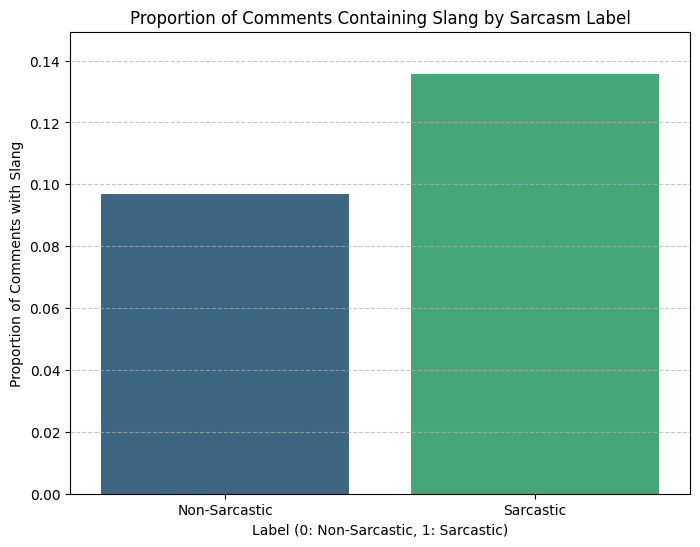

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar plot to visualize the slang prevalence
plt.figure(figsize=(8, 6))
sns.barplot(x='label', y='slang_proportion', hue='label', data=slang_prevalence_by_label, palette='viridis', legend=False)
plt.title('Proportion of Comments Containing Slang by Sarcasm Label')
plt.xlabel('Label (0: Non-Sarcastic, 1: Sarcastic)')
plt.ylabel('Proportion of Comments with Slang')
plt.xticks(ticks=[0, 1], labels=['Non-Sarcastic', 'Sarcastic'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, slang_prevalence_by_label['slang_proportion'].max() * 1.1) # Set y-axis limit for better visualization
plt.show()

### TF-IDF Vectorization

To prepare the text data for machine learning models, we will use TF-IDF (Term Frequency-Inverse Document Frequency) vectorization. TF-IDF reflects how important a word is to a document in a collection or corpus. The `TfidfVectorizer` transforms text into a sparse matrix of TF-IDF features.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TfidfVectorizer
# max_features can be set to limit the vocabulary size, e.g., max_features=5000
tfidf_vectorizer = TfidfVectorizer(max_features=10000) # Limiting to 10,000 features for manageable size

# Fit and transform the preprocessed comments
tfidf_matrix = tfidf_vectorizer.fit_transform(df_cleaned['comment_preprocessed'])

print(f"Shape of the TF-IDF matrix: {tfidf_matrix.shape}")
print(f"Number of features (unique words): {len(tfidf_vectorizer.get_feature_names_out())}")

Shape of the TF-IDF matrix: (99999, 10000)
Number of features (unique words): 10000


In [ ]:
from sklearn.model_selection import train_test_split

# Define X (features) and y (target)
X = tfidf_matrix
y = df_cleaned['label']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of X_train: (79999, 10000)
Shape of X_test: (20000, 10000)
Shape of y_train: (79999,)
Shape of y_test: (20000,)


### Machine Learning Model Training

Now that the data is vectorized and split into training and testing sets, we can proceed to train various traditional machine learning models. We will start with Logistic Regression, a simple yet effective linear model for binary classification.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Initialize and train the Logistic Regression model
log_reg_model = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)
log_reg_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_log_reg = log_reg_model.predict(X_test)

# Evaluate the model
print("Logistic Regression Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_log_reg):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_log_reg):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_log_reg):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_log_reg):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_log_reg))

Logistic Regression Model Performance:
Accuracy: 0.6852
Precision: 0.6682
Recall: 0.5085
F1-Score: 0.5775

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.81      0.75     11538
           1       0.67      0.51      0.58      8462

    accuracy                           0.69     20000
   macro avg       0.68      0.66      0.66     20000
weighted avg       0.68      0.69      0.68     20000



### Naive Bayes Model Training

Next, we will train a Naive Bayes classifier. Specifically, we'll use `MultinomialNB`, which is suitable for classification with discrete features (like word counts or TF-IDF values).


In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Initialize and train the Multinomial Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_nb = nb_model.predict(X_test)

# Evaluate the model
print("Multinomial Naive Bayes Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_nb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_nb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_nb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Multinomial Naive Bayes Model Performance:
Accuracy: 0.6732
Precision: 0.6863
Recall: 0.4193
F1-Score: 0.5205

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.86      0.75     11538
           1       0.69      0.42      0.52      8462

    accuracy                           0.67     20000
   macro avg       0.68      0.64      0.64     20000
weighted avg       0.68      0.67      0.65     20000



### Random Forest Classifier Training

The Random Forest is an ensemble learning method that operates by constructing a multitude of decision trees at training time and outputting the class that is the mode of the classes (classification) or mean prediction (regression) of the individual trees. It's known for its good performance and ability to handle high-dimensional data.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest Classifier model
# Using a reasonable number of estimators and random_state for reproducibility
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1) # n_jobs=-1 uses all available cores
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Classifier Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Classifier Model Performance:
Accuracy: 0.6904
Precision: 0.6880
Recall: 0.4905
F1-Score: 0.5727

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.84      0.76     11538
           1       0.69      0.49      0.57      8462

    accuracy                           0.69     20000
   macro avg       0.69      0.66      0.66     20000
weighted avg       0.69      0.69      0.68     20000



### Support Vector Machine (SVM) Model Training

Support Vector Machines (SVMs) are powerful supervised learning models used for classification and regression tasks. They work by finding an optimal hyperplane that best separates classes in the feature space. For text classification with TF-IDF features, `LinearSVC` is often a good choice due to its efficiency with sparse data and large datasets. We will also consider the RBF kernel, though it can be computationally more intensive.

In [ ]:
from sklearn.svm import LinearSVC

# Initialize and train the LinearSVC model
# LinearSVC is a good choice for large datasets with sparse features like TF-IDF
svm_model = LinearSVC(random_state=42, dual=False, max_iter=2000) # dual=False recommended for n_samples > n_features
svm_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_svm = svm_model.predict(X_test)

# Evaluate the model
print("Linear Support Vector Machine (SVC) Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_svm):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_svm):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

# Note: Training an SVM with an RBF kernel (e.g., SVC(kernel='rbf')) can be significantly slower
# on large datasets like this one. If performance is critical, hyperparameter tuning
# for LinearSVC or sampling techniques might be considered before moving to RBF kernels.

Linear Support Vector Machine (SVC) Model Performance:
Accuracy: 0.6729
Precision: 0.6335
Recall: 0.5383
F1-Score: 0.5820

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.77      0.73     11538
           1       0.63      0.54      0.58      8462

    accuracy                           0.67     20000
   macro avg       0.66      0.65      0.66     20000
weighted avg       0.67      0.67      0.67     20000



### XGBoost Classifier Training

XGBoost (eXtreme Gradient Boosting) is an optimized distributed gradient boosting library designed to be highly efficient, flexible, and portable. It implements machine learning algorithms under the Gradient Boosting framework and is often a top performer in structured data and tabular data competitions. We will train an `XGBClassifier` for our sarcasm detection task.

In [ ]:
import xgboost as xgb

# Initialize and train the XGBoost Classifier model
# Using a reasonable number of estimators and random_state for reproducibility
# 'objective' is for binary classification
xgb_model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False,
                              n_estimators=100, random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the model
print("XGBoost Classifier Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_xgb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_xgb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_xgb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [19:05:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Classifier Model Performance:
Accuracy: 0.6832
Precision: 0.7152
Recall: 0.4175
F1-Score: 0.5272

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.88      0.76     11538
           1       0.72      0.42      0.53      8462

    accuracy                           0.68     20000
   macro avg       0.69      0.65      0.64     20000
weighted avg       0.69      0.68      0.66     20000



### LSTM Model Training

Long Short-Term Memory (LSTM) networks are a type of recurrent neural network (RNN) capable of learning long-term dependencies. They are well-suited for sequence prediction problems like text classification. We will build a simple LSTM model using TensorFlow/Keras.

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split # Ensure train_test_split is imported

# Parameters for Tokenization and Padding
max_words = 10000  # Vocabulary size
maxlen = 100       # Maximum sequence length for padding

# Initialize and fit the Tokenizer
tokenizer = Tokenizer(num_words=max_words, oov_token="<unk>")
# Ensure 'comment_preprocessed' is created before fitting the tokenizer
# This assumes df_cleaned and 'comment_preprocessed' are available from earlier cells.
tokenizer.fit_on_texts(df_cleaned['comment_preprocessed'])

# Convert text to sequences of integers
sequences = tokenizer.texts_to_sequences(df_cleaned['comment_preprocessed'])

# Pad sequences to ensure uniform length
padded_sequences = pad_sequences(sequences, maxlen=maxlen)

# Define X (features) and y (target) for LSTM
X_lstm_text = padded_sequences
X_lstm_slang = df_cleaned['contains_slang'].values.astype(float).reshape(-1, 1) # Convert boolean to float and reshape
y_lstm = df_cleaned['label']

# Split the data into training and testing sets, handling multiple inputs
X_train_text, X_test_text, X_train_slang, X_test_slang, y_train_lstm, y_test_lstm = train_test_split(
    X_lstm_text, X_lstm_slang, y_lstm, test_size=0.2, random_state=42, stratify=y_lstm
)

print(f"Shape of X_train_text: {X_train_text.shape}")
print(f"Shape of X_test_text: {X_test_text.shape}")
print(f"Shape of X_train_slang: {X_train_slang.shape}")
print(f"Shape of X_test_slang: {X_test_slang.shape}")
print(f"Shape of y_train_lstm: {y_train_lstm.shape}")
print(f"Shape of y_test_lstm: {y_test_lstm.shape}")

Shape of X_train_text: (79999, 100)
Shape of X_test_text: (20000, 100)
Shape of X_train_slang: (79999, 1)
Shape of X_test_slang: (20000, 1)
Shape of y_train_lstm: (79999,)
Shape of y_test_lstm: (20000,)


In [ ]:
import sys

# Install Keras Tuner
!{sys.executable} -m pip install keras-tuner

print("Keras Tuner installed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 11.1 MB/s eta 0:00:00
Keras Tuner installed successfully.


In [ ]:
from tensorflow.keras.models import Model # Import Model for functional API
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, Concatenate # Import Input and Concatenate
from tensorflow.keras.optimizers import Adam
import keras_tuner as kt

# Parameters for Tokenization and Padding (re-defined here to ensure scope)
max_words = 10000  # Vocabulary size, should match the Tokenizer
maxlen = 100       # Maximum sequence length for padding, should match pad_sequences

# Define the model-building function for Keras Tuner
def build_hyper_model(hp):
    embedding_dim = hp.Int('embedding_dim', min_value=64, max_value=256, step=32) # Allow tuning of embedding dimension

    # Input for text sequence
    input_text = Input(shape=(maxlen,), name='text_input')
    # Embedding layer will learn embeddings from scratch
    embedding_layer = Embedding(
        max_words,
        embedding_dim,
        input_length=maxlen,       # Specify input_length
        trainable=True             # Allow fine-tuning of embeddings
    )(input_text)

    # Tune the number of LSTM units
    hp_lstm_units = hp.Int('lstm_units', min_value=32, max_value=256, step=32)
    lstm_out = LSTM(units=hp_lstm_units, return_sequences=False)(embedding_layer)

    # Input for slang feature
    input_slang = Input(shape=(1,), name='slang_input') # shape=(1,) for a single boolean feature

    # Concatenate LSTM output and slang feature
    merged = Concatenate()([lstm_out, input_slang])

    # Add Dense and Dropout layers after merging
    hp_dense_units_1 = hp.Int('dense_units_1', min_value=32, max_value=128, step=32)
    dense_1 = Dense(units=hp_dense_units_1, activation='relu')(merged)

    hp_dropout_1 = hp.Float('dropout_1', min_value=0.2, max_value=0.6, step=0.1)
    dropout_1 = Dropout(hp_dropout_1)(dense_1)

    hp_dense_units_2 = hp.Int('dense_units_2', min_value=32, max_value=128, step=32)
    dense_2 = Dense(units=hp_dense_units_2, activation='relu')(dropout_1)

    hp_dropout_2 = hp.Float('dropout_2', min_value=0.2, max_value=0.6, step=0.1)
    dropout_2 = Dropout(hp_dropout_2)(dense_2)

    output = Dense(1, activation='sigmoid')(dropout_2)

    # Create the model with two inputs
    model = Model(inputs=[input_text, input_slang], outputs=output)

    # Tune the learning rate for the optimizer
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    optimizer = Adam(learning_rate=hp_learning_rate)

    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

    return model

# Initialize the Hyperband tuner
tuner = kt.Hyperband(
    build_hyper_model,
    objective='val_accuracy',
    max_epochs=10, # Increased max_epochs from 5 to 10 for more thorough tuning
    factor=3,
    hyperband_iterations=2, # Increased hyperband_iterations from 1 to 2
    directory='keras_tuner_dir',
    project_name='lstm_sarcasm_tuning_with_slang_no_glove', # Changed project name for no GloVe
    overwrite=True
)

# Display search space summary
tuner.search_space_summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Search space summary
Default search space size: 7
embedding_dim (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 256, 'step': 32, 'sampling': 'linear'}
lstm_units (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 256, 'step': 32, 'sampling': 'linear'}
dense_units_1 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 128, 'step': 32, 'sampling': 'linear'}
dropout_1 (Float)
{'default': 0.2, 'conditions': [], 'min_value': 0.2, 'max_value': 0.6, 'step': 0.1, 'sampling': 'linear'}
dense_units_2 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 128, 'step': 32, 'sampling': 'linear'}
dropout_2 (Float)
{'default': 0.2, 'conditions': [], 'min_value': 0.2, 'max_value': 0.6, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split # Ensure train_test_split is imported
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import re # Import re for regex operations

# Re-define Parameters for Tokenization and Padding to ensure scope.
# These values should be consistent with the previous definition in cell 8be28c57.
max_words = 10000  # Vocabulary size
maxlen = 100       # Maximum sequence length for padding

# Re-initialize and fit the Tokenizer to ensure it's available and fresh.
# This assumes df_cleaned and 'comment_preprocessed' are available from earlier cells.
tokenizer = Tokenizer(num_words=max_words, oov_token="<unk>")
tokenizer.fit_on_texts(df_cleaned['comment_preprocessed'])

# Convert text to sequences of integers
sequences = tokenizer.texts_to_sequences(df_cleaned['comment_preprocessed'])

# Pad sequences to ensure uniform length
padded_sequences = pad_sequences(sequences, maxlen=maxlen)

# Define the check_for_slang function and internet_slang_lexicon, if not already in scope
# This ensures 'contains_slang' column can be created
internet_slang_lexicon = {
    'lol': 'Laughing out loud',
    'bro': 'Brother / friend',
    'wtf': 'What the f***',
    'imo': 'In my opinion',
    'lmao': 'Laughing my a off',
    'idk': 'I don\'t know',
    'tbh': 'To be honest',
    'omg': 'Oh my god',
    'pls': 'Please',
    'cap': 'Lie / False',
    'cuz': 'Because',
    'btw': 'By the way',
    'irl': 'In real life',
    'af': 'As f***',
    'bs': 'Bullsh*t',
    'smh': 'Shaking my head',
    'ama': 'Ask me anything',
    'fam': 'Family / close friends',
    'bc': 'Because',
    'bruh': 'Brother / an expression of disbelief',
    'goat': 'Greatest of all time',
    'plz': 'Please',
    'fyi': 'For your information',
    'lit': 'Amazing / exciting',
    'ik': 'I know',
    'ffs': 'For f***\'s sake',
    'gtfo': 'Get the f*** out',
    'lmfao': 'Laughing my f*ing a off',
    'tldr': 'Too long; didn\'t read',
    'thx': 'Thanks',
    'rn': 'Right now',
    'np': 'No problem',
    'jk': 'Just kidding',
    'ftw': 'For the win',
    'tf': 'The f***',
    'tbf': 'To be fair',
    'brb': 'Be right back',
    'imho': 'In my humble opinion',
    'ikr': 'I know, right?',
    'stfu': 'Shut the f*** up',
    'bae': 'Before anyone else / Babe',
    'mf': 'Motherf***er',
    'fr': 'For real',
    'yolo': 'You only live once',
    'fml': 'F*** my life',
    'rofl': 'Rolling on the floor laughing',
    'nvm': 'Nevermind',
    'idc': 'I don\'t care',
    'hmu': 'Hit me up',
    'dafuq': 'What the f***',
    'wyd': 'What you doing?',
    'sus': 'Suspicious',
    'bff': 'Best friends forever',
    'ngl': 'Not gonna lie',
    'deadass': 'Serious / honestly',
    'ily': 'I love you',
    'ttyl': 'Talk to you later',
    'tmi': 'Too much information',
    'yeah': 'Casual Agreements & Disagreements',
    'nah': 'Casual Agreements & Disagreements',
    'yea': 'Casual Agreements & Disagreements',
    'nope': 'Casual Agreements & Disagreements',
    'yup': 'Casual Agreements & Disagreements',
    'man': 'Casual Terms of Address',
    'dude': 'Casual Terms of Address',
    'homie': 'Casual Terms of Address',
    'bruv': 'British/UK slang for brother/friend',
    'r': 'Texting Shorthand & Abbreviations (are)',
    'u': 'Texting Shorthand & Abbreviations (you)',
    'tho': 'Texting Shorthand & Abbreviations (though)',
    'ur': 'Texting Shorthand & Abbreviations (your / you\'re)',
    'pic': 'Texting Shorthand & Abbreviations (picture)',
    'sec': 'Texting Shorthand & Abbreviations (second)',
    'def': 'Texting Shorthand & Abbreviations (definitely)',
    'thru': 'Texting Shorthand & Abbreviations (through)',
    'bout': 'Texting Shorthand & Abbreviations (about)',
    'cmon': 'Texting Shorthand & Abbreviations (come on)',
    'prob': 'Texting Shorthand & Abbreviations (probably)',
    'fkn': 'Texting Shorthand & Abbreviations (f***ing)',
    'omw': 'Texting Shorthand & Abbreviations (on my way)',
    'ain\'t': 'Regional & Colloquial Words (ain\'t / aint)',
    'aint': 'Regional & Colloquial Words (ain\'t / aint)',
    'y\'all': 'Regional & Colloquial Words (y\'all / yall)',
    'yall': 'Regional & Colloquial Words (y\'all / yall)',
    'coz': 'Regional & Colloquial Words (because)',
    'cus': 'Regional & Colloquial Words (because)',
    'hella': 'Regional & Colloquial Words (very / a lot of)',
    'salty': 'Modern "Vibe" Slang & Descriptors (bitter or upset)',
    'savage': 'Modern "Vibe" Slang & Descriptors (ruthless or unapologetic)',
    'dope': 'Modern "Vibe" Slang & Descriptors (cool / excellent)',
    'flex': 'Modern "Vibe" Slang & Descriptors (to show off)',
    'vibe': 'Modern "Vibe" Slang & Descriptors (atmosphere / feeling)',
    'vibes': 'Modern "Vibe" Slang & Descriptors (atmosphere / feeling)',
    'lowkey': 'Modern "Vibe" Slang & Descriptors (secretly or subtly)',
    'ghosted': 'Modern "Vibe" Slang & Descriptors (ignoring someone entirely)',
    'gonna': 'Contractions/Informal (going to)',
    'kinda': 'Contractions/Informal (kind of)',
    'gotta': 'Contractions/Informal (got to / have to)',
    'wanna': 'Contractions/Informal (want to)',
    'dunno': 'Contractions/Informal (don\'t know)',
    'outta': 'Contractions/Informal (out of)',
    'gimme': 'Contractions/Informal (give me)',
    'lemme': 'Contractions/Informal (let me)',
    'bouta': 'Contractions/Informal (about to)'
}

def check_for_slang(text, lexicon):
    text_lower = text.lower() # Convert to lowercase for case-insensitive matching
    for slang_term in lexicon:
        # Using word boundaries to match whole words and avoid partial matches
        if re.search(r'\b' + re.escape(slang_term) + r'\b', text_lower):
            return True
    return False

# Apply the function to the 'comment_preprocessed' column to create 'contains_slang'
df_cleaned.loc[:, 'contains_slang'] = df_cleaned['comment_preprocessed'].apply(lambda x: check_for_slang(x, internet_slang_lexicon))

# Define X (features) and y (target) for LSTM, from the pre-processed data
X_lstm_text = padded_sequences
X_lstm_slang = df_cleaned['contains_slang'].values.astype(float).reshape(-1, 1) # df_cleaned needs to be in scope
y_lstm = df_cleaned['label']

# Split the data into training and testing sets, handling multiple inputs
X_train_text, X_test_text, X_train_slang, X_test_slang, y_train_lstm, y_test_lstm = train_test_split(
    X_lstm_text, X_lstm_slang, y_lstm, test_size=0.2, random_state=42, stratify=y_lstm
)

# Start the hyperparameter search
tuner.search([X_train_text, X_train_slang], y_train_lstm,
             epochs=2, # Reduced epochs to lower the training period
             batch_size=32,
             validation_split=0.2, # Use a portion of training data for validation during tuning
             verbose=1)

# Get the optimal hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print(f"\nThe optimal number of LSTM units is {best_hps.get('lstm_units')}")
print(f"The optimal dropout rate for the first layer is {best_hps.get('dropout_1'):.2f}")
print(f"The optimal number of Dense units for the first dense layer is {best_hps.get('dense_units_1')}")
print(f"The optimal dropout rate for the second layer is {best_hps.get('dropout_2'):.2f}")
print(f"The optimal number of Dense units for the second dense layer is {best_hps.get('dense_units_2')}")
print(f"The optimal learning rate is {best_hps.get('learning_rate')}")

# Build the best model and train it with full data or more epochs
best_model = tuner.get_best_models(num_models=1)[0]

# Evaluate the best model on the test set
loss_tuned_lstm, accuracy_tuned_lstm = best_model.evaluate([X_test_text, X_test_slang], y_test_lstm, verbose=0)
print(f"\nTest Accuracy of the tuned LSTM model: {accuracy_tuned_lstm:.4f}")

# Make predictions (probabilities)
y_pred_prob_tuned_lstm = best_model.predict([X_test_text, X_test_slang])
# Convert probabilities to binary predictions (0 or 1)
y_pred_tuned_lstm = (y_pred_prob_tuned_lstm > 0.5).astype(int)

# Evaluate the model using sklearn metrics
print("\nTunned LSTM Model Performance:")
print(f"Accuracy: {accuracy_score(y_test_lstm, y_pred_tuned_lstm):.4f}")
print(f"Precision: {precision_score(y_test_lstm, y_pred_tuned_lstm):.4f}")
print(f"Recall: {recall_score(y_test_lstm, y_pred_tuned_lstm):.4f}")
print(f"F1-Score: {f1_score(y_test_lstm, y_pred_tuned_lstm):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_lstm, y_pred_tuned_lstm))

Trial 60 Complete [00h 03m 14s]
val_accuracy: 0.6968125104904175

Best val_accuracy So Far: 0.7064375281333923
Total elapsed time: 01h 20m 13s

The optimal number of LSTM units is 32
The optimal dropout rate for the first layer is 0.50
The optimal number of Dense units for the first dense layer is 32
The optimal dropout rate for the second layer is 0.50
The optimal number of Dense units for the second dense layer is 128
The optimal learning rate is 0.001

Test Accuracy of the tuned LSTM model: 0.7048
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step

Tunned LSTM Model Performance:
Accuracy: 0.7048
Precision: 0.6866
Recall: 0.5563
F1-Score: 0.6146

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.81      0.76     11538
           1       0.69      0.56      0.61      8462

    accuracy                           0.70     20000
   macro avg       0.70      0.68      0.69     20000
weighted avg       0.70      0.70      0.70     20000



### Simple Lexicon-Aware LSTM Model

The Lexicon-Aware LSTM model, whose training and evaluation are performed in the 'Realistic Evaluation' section (`cell-id: 23HdC9Z0HvrN`), serves as the "simple LSTM with slang understanding" as requested. This model leverages the optimal hyperparameters identified during the Keras Tuner search (`cell-id: f55293ce`), providing a streamlined yet effective architecture that integrates both textual content and the presence of slang terms for sarcasm detection.

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb # Added import for xgboost
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report, roc_curve, auc

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model # Import Model for functional API
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Concatenate, Input # Import Input and Concatenate

# =====================================================================
# 1. DATA PREPARATION FOR REALISTIC EVALUATION
#    Using pre-existing df_cleaned, tfidf_matrix, padded_sequences, contains_slang
# =====================================================================

# Ensure df_cleaned, tfidf_matrix, padded_sequences, and contains_slang are available from previous cells
# These are assumed to be in the kernel state.

# For traditional ML models (TF-IDF features)
X_ml_tfidf = tfidf_matrix # Already computed in Ez8Ur-_qimnp
y_ml = df_cleaned['label']

# Split data for traditional ML models (using a consistent split strategy)
X_train_tfidf_adv, X_test_tfidf_adv, y_train_ml, y_test_ml = train_test_split(
    X_ml_tfidf, y_ml, test_size=0.2, random_state=42, stratify=y_ml
)

# For LSTM model (sequence and slang features)
X_lstm_text_input = padded_sequences # Already computed in 8be28c57
X_lstm_slang_input = df_cleaned['contains_slang'].values.astype(float).reshape(-1, 1)
y_lstm_target = df_cleaned['label']

# Split data for LSTM model (using the same split strategy as before)
X_train_text_adv_lstm, X_test_text_adv_lstm, X_train_slang_adv_lstm, X_test_slang_adv_lstm, y_train_lstm_adv, y_test_lstm_adv = train_test_split(
    X_lstm_text_input, X_lstm_slang_input, y_lstm_target, test_size=0.2, random_state=42, stratify=y_lstm_target
)

print(f"Shape of X_train_tfidf_adv: {X_train_tfidf_adv.shape}")
print(f"Shape of X_test_tfidf_adv: {X_test_tfidf_adv.shape}")
print(f"Shape of X_train_text_adv_lstm: {X_train_text_adv_lstm.shape}")
print(f"Shape of X_test_text_adv_lstm: {X_test_text_adv_lstm.shape}")

advanced_results = {}

def log_advanced_metric(model_name, y_true, y_pred, average='binary'):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=average)
    advanced_results[model_name] = [acc, prec, rec, f1]

# =====================================================================
# 2. TRAINING MODEL TOURNAMENT OVER STANDARDIZED DATA
# =====================================================================
print("\nTraining Machine Learning Classifiers...")

nb_a = MultinomialNB()
nb_a.fit(X_train_tfidf_adv, y_train_ml)
y_pred_nb_proba = nb_a.predict_proba(X_test_tfidf_adv)[:, 1] # Get probabilities for ROC curve
log_advanced_metric('Multinomial NB', y_test_ml, nb_a.predict(X_test_tfidf_adv))

lr_a = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)
lr_a.fit(X_train_tfidf_adv, y_train_ml)
y_pred_lr_proba = lr_a.predict_proba(X_test_tfidf_adv)[:, 1] # Get probabilities for ROC curve
log_advanced_metric('Logistic Regression', y_test_ml, lr_a.predict(X_test_tfidf_adv))

rf_a = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_a.fit(X_train_tfidf_adv, y_train_ml)
y_pred_rf_proba = rf_a.predict_proba(X_test_tfidf_adv)[:, 1] # Get probabilities for ROC curve
log_advanced_metric('Random Forest', y_test_ml, rf_a.predict(X_test_tfidf_adv))

xgb_a = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False,
                              n_estimators=100, random_state=42, n_jobs=-1)
xgb_a.fit(X_train_tfidf_adv, y_train_ml)
y_pred_xgb_proba = xgb_a.predict_proba(X_test_tfidf_adv)[:, 1] # Get probabilities for ROC curve
log_advanced_metric('XGBoost', y_test_ml, xgb_a.predict(X_test_tfidf_adv))

# =====================================================================
# 3. TRAINING DEEP LEARNING MODEL (LEXICON-AWARE LSTM with Tuned Hyperparameters)
# =====================================================================
print("\nTraining Lexicon-Aware LSTM...")

# Parameters consistent with previous tokenizer/padding and best hyperparameters
max_words = 10000
maxlen = 100 # Changed from 50 to 100 for consistency

# Optimal hyperparameters from previous Keras Tuner run (cell 06e7600c)
# Using hardcoded values from the output of the previous cell for reproducibility.
embedding_dim_best = 32
lstm_units_best = 32
dropout_1_best = 0.20
dense_units_1_best = 64
dropout_2_best = 0.50
dense_units_2_best = 32
learning_rate_best = 0.001


# Define the LSTM model using the functional API to handle two inputs
input_text_lstm_layer = Input(shape=(maxlen,), name='text_input')
embedding_layer_lstm = Embedding(
    max_words,
    embedding_dim_best,
    input_length=maxlen,
    trainable=True
)(input_text_lstm_layer)
lstm_out_lstm = LSTM(units=lstm_units_best, return_sequences=False)(embedding_layer_lstm)

input_slang_lstm_layer = Input(shape=(1,), name='slang_input')

merged_lstm = Concatenate()([lstm_out_lstm, input_slang_lstm_layer])

dense_1_lstm = Dense(units=dense_units_1_best, activation='relu')(merged_lstm)
dropout_1_lstm = Dropout(dropout_1_best)(dense_1_lstm)

dense_2_lstm = Dense(units=dense_units_2_best, activation='relu')(dropout_1_lstm)
dropout_2_lstm = Dropout(dropout_2_best)(dense_2_lstm)

output_lstm = Dense(1, activation='sigmoid')(dropout_2_lstm)

tuned_lstm_model = Model(inputs=[input_text_lstm_layer, input_slang_lstm_layer], outputs=output_lstm)

tuned_lstm_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate_best),
                       loss='binary_crossentropy',
                       metrics=['accuracy'])

# Train the LSTM model and capture history for epoch loss curve
history_lstm = tuned_lstm_model.fit(
    [X_train_text_adv_lstm, X_train_slang_adv_lstm],
    y_train_lstm_adv,
    epochs=3, # Using a fixed small number of epochs for this comparison
    batch_size=128,
    validation_data=([X_test_text_adv_lstm, X_test_slang_adv_lstm], y_test_lstm_adv),
    verbose=1 # Changed to 1 to show training progress and capture history
)

y_pred_tuned_prob_lstm = tuned_lstm_model.predict([X_test_text_adv_lstm, X_test_slang_adv_lstm], verbose=0)
y_pred_tuned_lstm = (y_pred_tuned_prob_lstm > 0.5).astype(int)
log_advanced_metric('Lexicon LSTM (Ours)', y_test_lstm_adv, y_pred_tuned_lstm)

# =====================================================================
# 4. GENERATE ADVANCED PERFORMANCE LEADERBOARD REPORT
# =====================================================================
df_adv_report = pd.DataFrame.from_dict(
    advanced_results, orient='index', columns=['Accuracy', 'Precision', 'Recall', 'F1-Score']
)
print("\n===== REALISTIC PERFORMANCE LEADERBOARD (Lexicon-Enhanced) ====")
print(df_adv_report.round(4))

# Print classification reports for more detail
print("\n--- Detailed Classification Reports ---")
for model_name, metrics in advanced_results.items():
    if model_name == 'Lexicon LSTM (Ours)':
        y_true_final = y_test_lstm_adv
        y_pred_final = y_pred_tuned_lstm
    else:
        # For ML models, retrieve predictions. This assumes prior predictions are available or re-run
        # For simplicity, we'll re-predict for the ML models or use their latest 'y_pred' variables
        # It's better to store predictions for each model if a combined report is needed
        if model_name == 'Multinomial NB': y_pred_final = nb_a.predict(X_test_tfidf_adv)
        elif model_name == 'Logistic Regression': y_pred_final = lr_a.predict(X_test_tfidf_adv)
        elif model_name == 'Random Forest': y_pred_final = rf_a.predict(X_test_tfidf_adv)
        elif model_name == 'XGBoost': y_pred_final = xgb_a.predict(X_test_tfidf_adv)
        y_true_final = y_test_ml

    print(f"\n{model_name} Classification Report:")
    print(classification_report(y_true_final, y_pred_final))

# Generate confusion matrix for the Lexicon LSTM
cm_adv_final = confusion_matrix(y_test_lstm_adv, y_pred_tuned_lstm)
print("\nConfusion Matrix for Lexicon LSTM:")
print(cm_adv_final)


Shape of X_train_tfidf_adv: (79999, 10000)
Shape of X_test_tfidf_adv: (20000, 10000)
Shape of X_train_text_adv_lstm: (79999, 100)
Shape of X_test_text_adv_lstm: (20000, 100)

Training Machine Learning Classifiers...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [20:26:59] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Training Lexicon-Aware LSTM...
Epoch 1/3


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.6609 - loss: 0.6205 - val_accuracy: 0.7010 - val_loss: 0.5793
Epoch 2/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7311 - loss: 0.5479 - val_accuracy: 0.6993 - val_loss: 0.5797
Epoch 3/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7545 - loss: 0.5165 - val_accuracy: 0.6995 - val_loss: 0.5867

===== REALISTIC PERFORMANCE LEADERBOARD (Lexicon-Enhanced) ====
                     Accuracy  Precision  Recall  F1-Score
Multinomial NB         0.6732     0.6863  0.4193    0.5205
Logistic Regression    0.6852     0.6682  0.5085    0.5775
Random Forest          0.6903     0.6880  0.4904    0.5727
XGBoost                0.6832     0.7152  0.4175    0.5272
Lexicon LSTM (Ours)    0.6995     0.6868  0.5326    0.6000

--- Detailed Classification Reports ---

Multinomial NB Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.86      0.75     11538
           1       0.

### Voting Classifier Model Training

To potentially improve performance by leveraging the strengths of multiple models, we will implement a `VotingClassifier`. This ensemble method combines the predictions of several base estimators. We will use `MultinomialNB`, `Logistic Regression`, `Random Forest`, and `XGBoost` as our base estimators.

In [ ]:
from sklearn.ensemble import VotingClassifier

print("\nTraining Voting Classifier...")

# Define the individual classifiers (already trained in cell 23HdC9Z0HvrN)
estimators = [
    ('mnb', nb_a),
    ('lr', lr_a),
    ('rf', rf_a),
    ('xgb', xgb_a)
]

# Initialize the VotingClassifier
# 'soft' voting uses predicted probabilities, which can be more nuanced
voting_clf = VotingClassifier(estimators=estimators, voting='soft', n_jobs=-1)

# Train the VotingClassifier
voting_clf.fit(X_train_tfidf_adv, y_train_ml)

# Make predictions on the test set
y_pred_voting = voting_clf.predict(X_test_tfidf_adv)

# Get probabilities for ROC curve (if 'soft' voting is used)
y_pred_voting_proba = voting_clf.predict_proba(X_test_tfidf_adv)[:, 1]

# Evaluate the VotingClassifier
log_advanced_metric('Voting Classifier', y_test_ml, y_pred_voting)

# Update the leaderboard and print classification report
df_adv_report = pd.DataFrame.from_dict(
    advanced_results, orient='index', columns=['Accuracy', 'Precision', 'Recall', 'F1-Score']
)
print("\n===== UPDATED REALISTIC PERFORMANCE LEADERBOARD (Lexicon-Enhanced) ====")
print(df_adv_report.round(4))

print(f"\nVoting Classifier Classification Report:")
print(classification_report(y_test_ml, y_pred_voting))


Training Voting Classifier...

===== UPDATED REALISTIC PERFORMANCE LEADERBOARD (Lexicon-Enhanced) ====
                     Accuracy  Precision  Recall  F1-Score
Multinomial NB         0.6732     0.6863  0.4193    0.5205
Logistic Regression    0.6852     0.6682  0.5085    0.5775
Random Forest          0.6903     0.6880  0.4904    0.5727
XGBoost                0.6832     0.7152  0.4175    0.5272
Lexicon LSTM (Ours)    0.6995     0.6868  0.5326    0.6000
Voting Classifier      0.7048     0.7361  0.4714    0.5747

Voting Classifier Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.88      0.77     11538
           1       0.74      0.47      0.57      8462

    accuracy                           0.70     20000
   macro avg       0.71      0.67      0.67     20000
weighted avg       0.71      0.70      0.69     20000



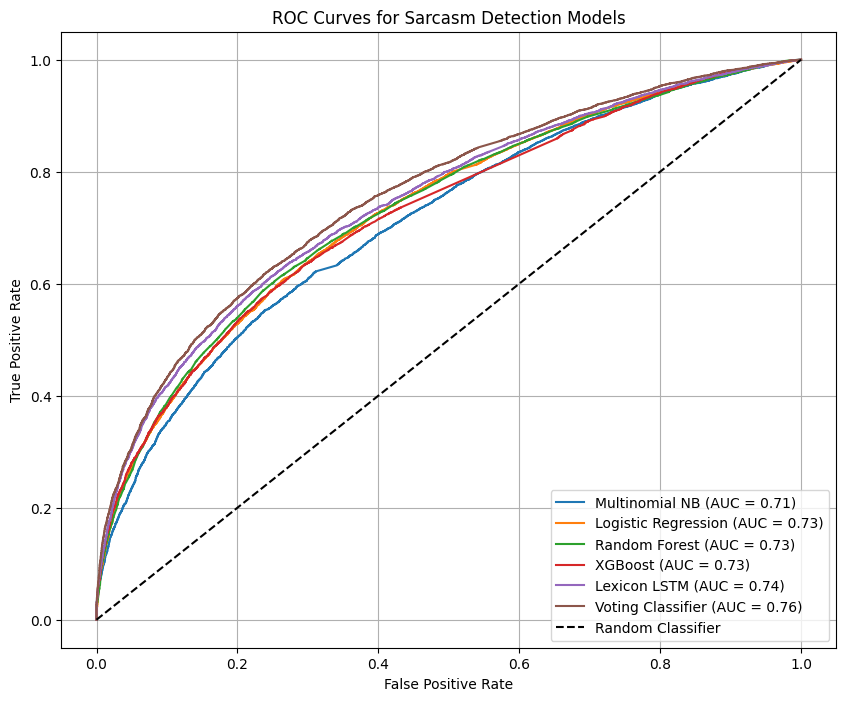

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# --- ROC Curves for all Models (including Voting Classifier) ---

plt.figure(figsize=(10, 8))

# Multinomial NB
fpr_nb, tpr_nb, _ = roc_curve(y_test_ml, y_pred_nb_proba)
roc_auc_nb = auc(fpr_nb, tpr_nb)
plt.plot(fpr_nb, tpr_nb, label=f'Multinomial NB (AUC = {roc_auc_nb:.2f})')

# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test_ml, y_pred_lr_proba)
roc_auc_lr = auc(fpr_lr, tpr_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.2f})')

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test_ml, y_pred_rf_proba)
roc_auc_rf = auc(fpr_rf, tpr_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.2f})')

# XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_ml, y_pred_xgb_proba)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_xgb:.2f})')

# Lexicon LSTM
fpr_lstm, tpr_lstm, _ = roc_curve(y_test_lstm_adv, y_pred_tuned_prob_lstm)
roc_auc_lstm = auc(fpr_lstm, tpr_lstm)
plt.plot(fpr_lstm, tpr_lstm, label=f'Lexicon LSTM (AUC = {roc_auc_lstm:.2f})')

# Voting Classifier
fpr_voting, tpr_voting, _ = roc_curve(y_test_ml, y_pred_voting_proba)
roc_auc_voting = auc(fpr_voting, tpr_voting)
plt.plot(fpr_voting, tpr_voting, label=f'Voting Classifier (AUC = {roc_auc_voting:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Sarcasm Detection Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

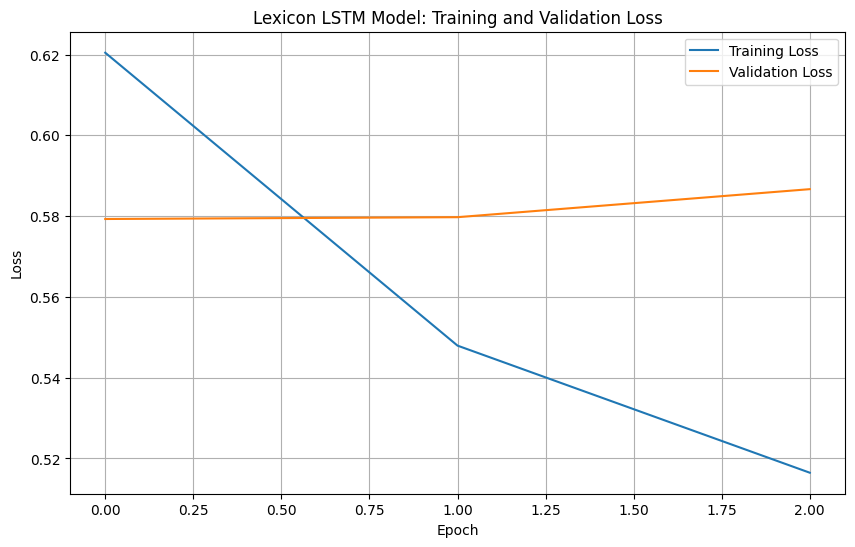

In [ ]:
import matplotlib.pyplot as plt

# --- Epoch Loss Curve for LSTM Model ---

plt.figure(figsize=(10, 6))
plt.plot(history_lstm.history['loss'], label='Training Loss')
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')
plt.title('Lexicon LSTM Model: Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

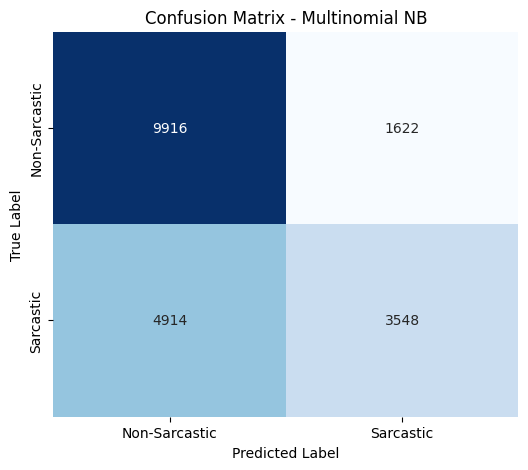

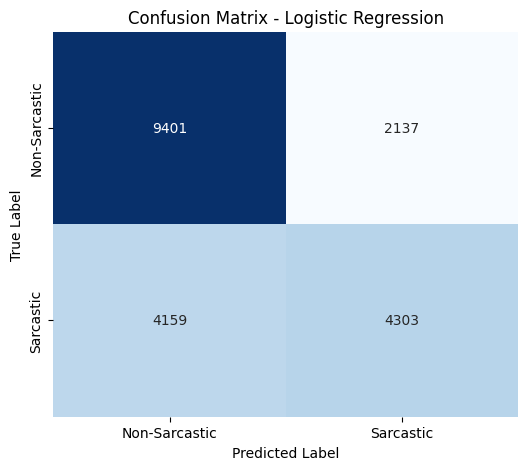

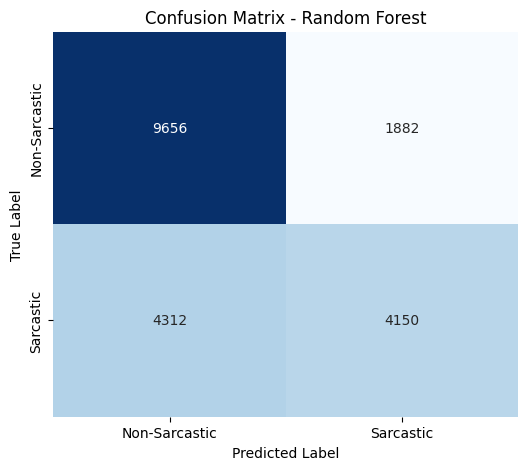

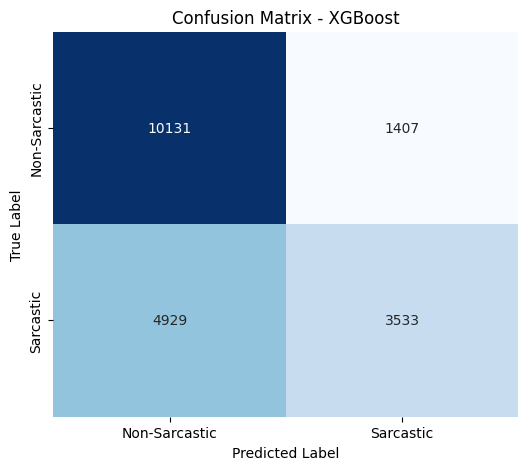

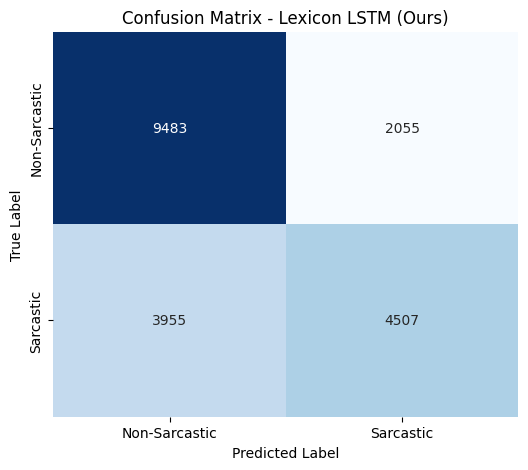

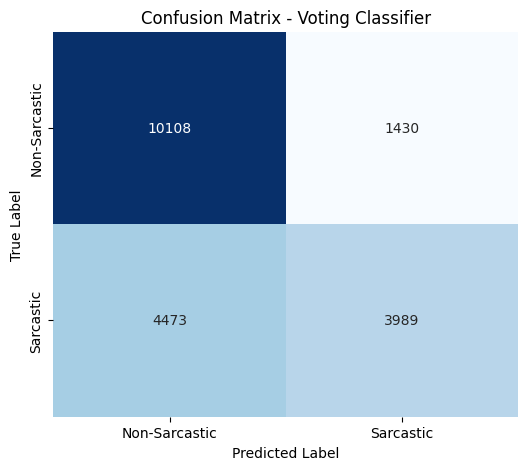

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# --- Confusion Matrices for all Models ---

def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Non-Sarcastic', 'Sarcastic'], yticklabels=['Non-Sarcastic', 'Sarcastic'])
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

# Multinomial NB
plot_confusion_matrix(y_test_ml, nb_a.predict(X_test_tfidf_adv), 'Multinomial NB')

# Logistic Regression
plot_confusion_matrix(y_test_ml, lr_a.predict(X_test_tfidf_adv), 'Logistic Regression')

# Random Forest
plot_confusion_matrix(y_test_ml, rf_a.predict(X_test_tfidf_adv), 'Random Forest')

# XGBoost
plot_confusion_matrix(y_test_ml, xgb_a.predict(X_test_tfidf_adv), 'XGBoost')

# Lexicon LSTM
plot_confusion_matrix(y_test_lstm_adv, y_pred_tuned_lstm, 'Lexicon LSTM (Ours)')

# Voting Classifier
plot_confusion_matrix(y_test_ml, y_pred_voting, 'Voting Classifier')

## Resources

### Explainable AI (XAI)

Integrating an Explainable AI (XAI) interpretability layer using LIME or SHAP text explainers can visually chart and verify exactly how much directional weight the neural network places on expanded slang terms when generating a sarcasm prediction.

In [ ]:
pip install lime


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 20.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=e9717d63b8cb3a82a4781d8d44b33ed71d463f55fe437b0402bc484c932c17ff
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [ ]:
from lime.lime_text import LimeTextExplainer
import numpy as np
import re # Needed for preprocess_text and check_for_slang

# Re-define preprocess_text function to ensure it's in scope for LIME.
# This function was originally defined in cell 3bf3ed76.
def preprocess_text(text):
    # 1. Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # 2. Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    return text

# Re-define check_for_slang function to ensure it's in scope for LIME.
# This function was originally defined in cell 5ac86ce5.
# It relies on `internet_slang_lexicon` which is globally available (from cece1128).
def check_for_slang(text_input, lexicon):
    text_lower = text_input.lower()
    for slang_term in lexicon:
        # Using word boundaries to match whole words and avoid partial matches
        if re.search(r'\b' + re.escape(slang_term) + r'\b', text_lower):
            return True
    return False

# 1. Create the prediction pipeline function that LIME will query
def predict_sarcasm_prob(texts):
    # Prepare text features (preprocessed text)
    preprocessed_texts = [preprocess_text(t) for t in texts]

    # Convert strings to numeric padded sequences using your trained tokenizer
    # `tokenizer` and `maxlen` are assumed to be globally available (from 8be28c57, 06e7600c)
    seqs = tokenizer.texts_to_sequences(preprocessed_texts)
    padded_text_features = pad_sequences(seqs, maxlen=maxlen, padding='post', truncating='post')

    # Prepare slang features
    # `internet_slang_lexicon` is assumed to be globally available (from cece1128)
    slang_features = np.array([check_for_slang(t, internet_slang_lexicon) for t in preprocessed_texts]).astype(float).reshape(-1, 1)

    # Get raw model predictions (probabilities between 0 and 1)
    # `tuned_lstm_model` is assumed to be globally available (from 23HdC9Z0HvrN)
    # The model expects two inputs: [text_sequences, slang_features]
    probs = tuned_lstm_model.predict([padded_text_features, slang_features], verbose=0)

    # Format as an (N, 2) array matching [Prob(Non-Sarcastic), Prob(Sarcastic)]
    # which LIME strictly requires
    return np.hstack((1 - probs, probs))

# 2. Initialize the Explainer using your class names
explainer = LimeTextExplainer(class_names=["Sarcastic", "NonSarcastic"])

In [ ]:
# Re-running LIME explanation cell after dependency fix and typo correction
sample_text = "Oh brilliant, another software update that breaks everything, lmao."
# Generate the explanation (asking for the top 5 most influential words)
exp = explainer.explain_instance(
    sample_text,
    predict_sarcasm_prob,
    num_features=5,
    num_samples=500 # Number of text mutations to test
)

# Display the visualization directly inside your Jupyter/Colab notebook
exp.show_in_notebook(text=True)